In [5]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append(r"C:\Users\dillo\OneDrive\Documents\Projects\Microsoft Mind")
import numpy as np, pandas as pd
import pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from src.db import get_engine
from src.eval import evaluate, per_impression_ndcg, ndcg_at_k, mrr
from src.recommenders import content_recommender, popularity_recommender
from src.metrics import intra_list_diversity
engine = get_engine()

emb = np.load("../models/news_emb.npy")
news_ids = np.load("../models/news_emb_ids.npy", allow_pickle=True)
row_of = {n: i for i, n in enumerate(news_ids)}

train_clicks = pd.read_sql("SELECT news_id, SUM(clicked) AS clicks FROM fact_impressions GROUP BY news_id",
                           engine).set_index("news_id")["clicks"].to_dict()
meta = pd.read_sql("SELECT news_id, category, subcategory FROM dim_news", engine)
cat_of    = dict(zip(meta.news_id, meta.category))
subcat_of = dict(zip(meta.news_id, meta.subcategory))

def parse(s): return [(nid, int(l)) for nid, l in (x.split('-') for x in s.split())]
def profile_from_history(h):
    if not isinstance(h, str) or not h.strip(): return None
    c, s = Counter(), Counter()
    for nid in h.split():
        if nid in cat_of:    c[cat_of[nid]] += 1
        if nid in subcat_of: s[subcat_of[nid]] += 1
    t = sum(c.values())
    return {"cats": c, "subs": s, "total": t} if t else None

dev = pd.read_csv("../data/raw/MINDsmall_dev/behaviors.tsv", sep="\t",
       names=["impression_id","user_id","time","history","impressions"])
dev["parsed"]  = dev["impressions"].apply(parse)
dev["profile"] = dev["history"].apply(profile_from_history)

base_score = content_recommender(cat_of, subcat_of, train_clicks)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
def _minmax(x):
    x = np.asarray(x, dtype=float)
    lo, hi = x.min(), x.max()
    return (x - lo) / (hi - lo) if hi > lo else np.zeros_like(x)

def mmr_ranker(row, lam=0.3):
    cands = [nid for nid, _ in row.parsed]
    n = len(cands)
    base = _minmax([base_score(row, c) for c in cands])      

    idx  = [row_of.get(c) for c in cands]
    have = np.array([i is not None for i in idx])
    V = np.zeros((n, emb.shape[1]))
    for r, i in enumerate(idx):
        if i is not None:
            V[r] = emb[i]

    order, chosen = [], np.zeros(n, bool)
    max_sim = np.zeros(n)                                    
    for step in range(n):
        div = np.ones(n) if step == 0 else (1 - max_sim)     
        val = (1 - lam) * base + lam * div
        val[chosen] = -np.inf
        j = int(np.argmax(val))
        order.append(cands[j]); chosen[j] = True
        if have[j]:                                          
            sims = V @ V[j]; sims[~have] = 0
            max_sim = np.maximum(max_sim, sims)
    return order

In [3]:
def evaluate_ranker(ranker, dev, k=10):
    ndcgs, mrrs, divs = [], [], []
    for row in dev.itertuples(index=False):
        parsed = row.parsed
        if sum(l for _, l in parsed) == 0:
            continue
        order = ranker(row)
        lab = dict(parsed)
        labels = [lab[nid] for nid in order]
        ndcgs.append(ndcg_at_k(labels, k))
        mrrs.append(mrr(labels))
        divs.append(intra_list_diversity(order[:k], emb, row_of))
    return {"nDCG@10": np.mean(ndcgs), "MRR": np.mean(mrrs),
            "diversity@10": np.nanmean(divs)}

In [4]:
sub = dev.head(5000)

print("lam=0.0 :", evaluate_ranker(lambda r: mmr_ranker(r, lam=0.0), sub))
print("lam=0.3 :", evaluate_ranker(lambda r: mmr_ranker(r, lam=0.3), sub))

lam=0.0 : {'nDCG@10': np.float64(0.36242554681532946), 'MRR': np.float64(0.32408670979541004), 'diversity@10': np.float64(0.9170472550142498)}
lam=0.3 : {'nDCG@10': np.float64(0.3620459636920372), 'MRR': np.float64(0.32293868886263255), 'diversity@10': np.float64(0.9274744461726881)}


In [6]:
lams = [0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]
rows = []
for lam in lams:
    r = evaluate_ranker(lambda row, l=lam: mmr_ranker(row, lam=l), sub)   # l=lam captures the value!
    r["lambda"] = lam
    rows.append(r)
sweep = pd.DataFrame(rows).set_index("lambda")
print(sweep)

         nDCG@10       MRR  diversity@10
lambda                                  
0.0     0.362426  0.324087      0.917047
0.1     0.362074  0.323571      0.923493
0.2     0.362238  0.323551      0.925114
0.3     0.362046  0.322939      0.927474
0.5     0.360030  0.320834      0.935731
0.7     0.347447  0.313030      0.951910
0.9     0.327546  0.297291      0.984890


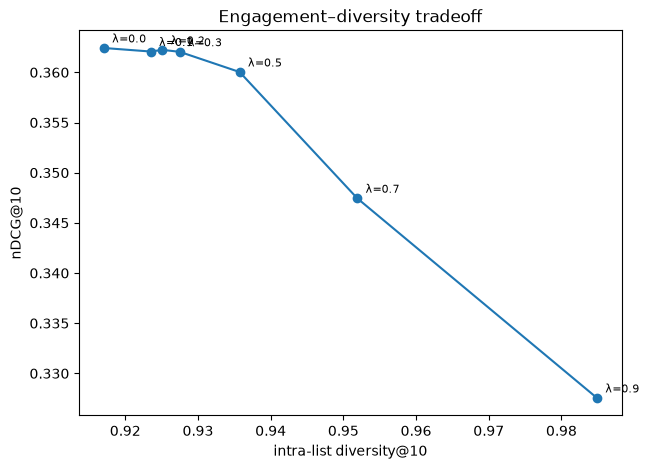

In [8]:
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(sweep["diversity@10"], sweep["nDCG@10"], "o-")
for lam, r in sweep.iterrows():
    ax.annotate(f"λ={lam}", (r["diversity@10"], r["nDCG@10"]),
                textcoords="offset points", xytext=(6,4), fontsize=8)
ax.set_xlabel("intra-list diversity@10"); ax.set_ylabel("nDCG@10")
ax.set_title("Engagement–diversity tradeoff")
fig.savefig("../figures/tradeoff_curve.png", dpi=200, bbox_inches="tight")
plt.show()